# 06.1 · Linear regression: how many copies a year can a new Kindle book expect?

**Project:** Digital Publishing Opportunity Intelligence

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

## 1. TL;DR

**Key findings**

- Linear regression explains **22.4%** of the differences in copies between **11,015 test books** from new authors (R², log scale), against 0% for the baseline.
- It is within 2 times of the real copies for **29.6%** of the books (baseline 25.4%).
- The **publishing route** (a large publisher goes with **3.85 times** more copies) and the **author's earlier books** are the strongest signs.
- It cannot predict hits: their real median is 24,586 copies, the predicted one 317.

## 2. Recap

**Question.** How many copies a year can a new Kindle book expect, from its niche, price, length, series, publishing route and the
author's experience?

**From the EDA (`04_eda_with_synthetic_sales.ipynb`).** The table has **55,690 books** published from 2019 to 2021, each with the
number of copies sold per year (`copies_per_year`). The copies sold are **synthetic example data** (`03_synthetic_sales_generation.ipynb`),
so the results show how the method works, not real Amazon sales.

**This notebook** trains one regression model and compares it with a simple baseline: split the data, tune on the training books only,
and look at the test books once at the end. Notebook `06.4` compares the three models, turns copies into income, and answers the
sub-question for less-known authors without hits.

## 3. Setup

I load the libraries and the table from the EDA. `RANDOM_STATE` makes the split and the model the same every time.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
PROCESSED = PROJECT / "data" / "processed"
MODELS_DIR = PROJECT / "models"
MODELS_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
TARGET = "copies_per_year"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

books = pd.read_parquet(PROCESSED / "kindle_books_sales_income.parquet")
print("Table:", books.shape)
books[["title", "niche", "route", "price", "pages", "is_series", "author_earlier_books", TARGET]].head(3).round(2)

Table: (55690, 18)


,title,niche,route,price,pages,is_series,author_earlier_books,copies_per_year
0,Back To You,Literature & Fiction,small publisher,6.99,254.0,0,0,120.41
1,Steele's War: A Damascus Steele novel (The Glo...,Science Fiction & Fantasy,small publisher,3.99,365.0,1,27,74.63
2,'Charlotte's Search' Box Set Two: A Tale of BD...,Literature & Fiction,small publisher,3.99,454.0,1,67,239.74


- The table has **55,690 books** and 18 columns, one row per book. `copies_per_year` is the target.

## 4. Feature preparation

**The target.** Sales are very uneven: most books sell a few dozen copies a year and a few sell hundreds of thousands. A model trained on the
raw numbers would try mostly to fit these few hits. So the model learns the **logarithm** of copies, `log_copies = log(1 + copies)`
(`np.log1p`, which also works for 0). At the end I turn the prediction back into copies with `np.expm1`. This step goes beyond the course;
it is the usual way to handle such skewed numbers. The charts show the target before and after.

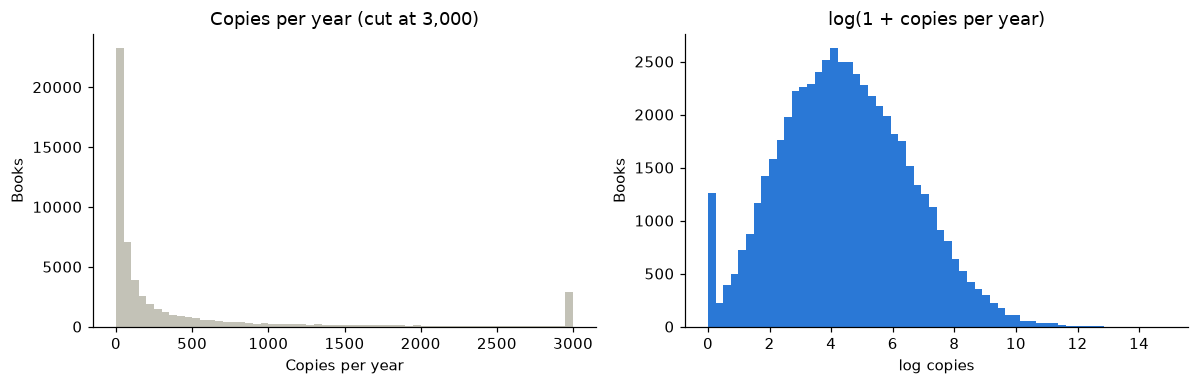

Copies: median 78, mean 973, max 2,803,289
Books above 3,000 copies (not shown on the left): 2,883
log copies: median 4.37, mean 4.47, max 14.85


In [2]:
books["log_copies"] = np.log1p(books[TARGET])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(books[TARGET].clip(upper=3000), bins=60, color=GREY)
axes[0].set_title("Copies per year (cut at 3,000)")
axes[0].set_xlabel("Copies per year")
axes[1].hist(books["log_copies"], bins=60, color=BLUE)
axes[1].set_title("log(1 + copies per year)")
axes[1].set_xlabel("log copies")
for ax in axes:
    ax.set_ylabel("Books")
plt.tight_layout()
plt.show()
print(f"Copies: median {books[TARGET].median():.0f}, mean {books[TARGET].mean():.0f}, max {books[TARGET].max():,.0f}")
print(f"Books above 3,000 copies (not shown on the left): {(books[TARGET] > 3000).sum():,}")
print(f"log copies: median {books['log_copies'].median():.2f}, mean {books['log_copies'].mean():.2f}, max {books['log_copies'].max():.2f}")

- The raw copies are very skewed: median **78**, mean **973**, and the largest book **2.8 million**. **2,883** books are above 3,000 and are not even on the left chart.
- After the logarithm the books form one hill around **4.37** (about 78 copies). This is a shape a regression model can learn.

**The features** are things an author knows before publishing: niche, price, pages, series, publishing route and the author's earlier
books. Publication year, ratings and the share of verified buyers are known only after publication, so I do not use them.

Linear regression works with straight lines, and `price` and `author_earlier_books` are very skewed. So I use their logarithms. `niche` and
`route` become 0/1 columns.

In [3]:
def prepare_features(data):
    data = data.copy()
    data["log_price"] = np.log(data["price"])
    data["log_earlier_books"] = np.log1p(data["author_earlier_books"])
    return data


CONTINUOUS = ["pages", "log_price", "log_earlier_books"]
BINARY = ["is_series"]
CATEGORICAL = ["niche", "route"]
FEATURES = CONTINUOUS + BINARY + CATEGORICAL
books = prepare_features(books)
print("Features:", FEATURES)
books[FEATURES].isna().sum().to_frame("empty values").T

Features: ['pages', 'log_price', 'log_earlier_books', 'is_series', 'niche', 'route']


,pages,log_price,log_earlier_books,is_series,niche,route
empty values,2659,0,0,0,0,0


- The model gets **6 features**: 3 continuous, 1 binary and 2 categories.
- Only `pages` has empty values (**2,659** books), and the pipeline fills them with the median of the training books.

## 5. Train/test split

I keep **20% of the books for the final test**. All books of one author stay on the same side, so the test shows how the model works for
**authors it has not seen**. `GroupKFold` does this; I use its first fold as the test set. It goes one step beyond the plain
`train_test_split` from the course, as in part 1.

In [4]:
groups = books["author"].fillna(books["parent_asin"])
X, y = books[FEATURES], books["log_copies"]
splitter = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_index, test_index = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]
groups_train, groups_test = groups.iloc[train_index], groups.iloc[test_index]
test_books = books.iloc[test_index].copy()

print(f"Training books: {len(X_train):,} (median {np.expm1(y_train.median()):.0f} copies) | authors: {groups_train.nunique():,}")
print(f"Test books:     {len(X_test):,} (median {np.expm1(y_test.median()):.0f} copies) | authors: {groups_test.nunique():,}")
print("Authors on both sides:", len(set(groups_train) & set(groups_test)))

Training books: 44,675 (median 79 copies) | authors: 32,061
Test books:     11,015 (median 77 copies) | authors: 8,016
Authors on both sides: 0


- **44,675 training books** and **11,015 test books**, with a similar median (79 and 77 copies a year).
- **No author is on both sides** (0 shared authors), so the test really shows new authors.

## 6. Baseline

The baseline ignores the book and always predicts the **median** of the training books. A model is useful only if it does better. The
function `measures` calculates the same numbers for every model:

- **R² (log)**: the share of differences between books that the model explains, on the log scale. 0 means no better than the baseline, 1 is perfect.
- **MAE (log)**: the average error on the log scale. An error of 0.69 means about 2 times too many or too few copies.
- **MAE (copies)**: the average error in copies. Hits make it large.
- **Median error (copies)**: the error of a typical book in copies.

In [5]:
def measures(name, true_log, predicted_log):
    true_copies, predicted_copies = np.expm1(true_log), np.expm1(predicted_log)
    return {"model": name, "R2 (log)": r2_score(true_log, predicted_log), "MAE (log)": mean_absolute_error(true_log, predicted_log),
            "MAE (copies)": mean_absolute_error(true_copies, predicted_copies),
            "median error (copies)": median_absolute_error(true_copies, predicted_copies)}


baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
baseline_prediction = baseline.predict(X_test)
print(f"The baseline predicts {np.expm1(baseline_prediction[0]):.0f} copies a year for every book")
pd.DataFrame([measures("baseline (test)", y_test, baseline_prediction)]).set_index("model").round(3)

The baseline predicts 79 copies a year for every book


,R2 (log),MAE (log),MAE (copies),median error (copies)
model,,,,
baseline (test),-0.002,1.684,876.067,72.274


- The baseline predicts **79 copies a year** for every book. Its R² is **−0.002**, so it explains nothing, as expected.
- Its typical error is **72 copies** and its mean error **876 copies**: the mean is large because of the hits.
- On the log scale it is off by **1.68** on average, which is about **5 times** too many or too few copies.

## 7. Candidate model

**Linear regression** gives each feature a weight and adds them up. I use **Ridge**, the linear regression from the course with
regularization: `alpha` keeps the weights small, which helps when niches and routes add many columns.

- The **pipeline** fills empty `pages` with the median, scales the continuous features and turns `niche` and `route` into 0/1 columns, with
  *Literature & Fiction* and *self-published* as the reference groups. All of this is learned from training books only.
- `GridSearchCV` tries several values of `alpha` with 5 folds, keeps authors together in each fold, and chooses by R².

In [6]:
preprocess = ColumnTransformer([
    ("continuous", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), CONTINUOUS),
    ("binary", "passthrough", BINARY),
    ("category", OneHotEncoder(drop=["Literature & Fiction", "self-published"], handle_unknown="ignore"), CATEGORICAL),
])
pipeline = Pipeline([("prepare", preprocess), ("model", Ridge())])
grid = {"model__alpha": [0.1, 1, 10, 100]}

cv = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipeline, grid, scoring="r2", cv=cv, return_train_score=True)
search.fit(X_train, y_train, groups=groups_train)
best_model = search.best_estimator_

columns = [c for c in pd.DataFrame(search.cv_results_).columns if c.startswith("param_")]
results = pd.DataFrame(search.cv_results_)[columns + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]]
results.columns = [c.replace("param_model__", "") for c in results.columns]
print("Best settings:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})
print(f"Best validation R2 (log): {search.best_score_:.4f}")
results.sort_values("rank_test_score").round(4)

Best settings: {'alpha': 10}
Best validation R2 (log): 0.2155


,alpha,mean_train_score,mean_test_score,std_test_score,rank_test_score
2,10.0,0.2191,0.2155,0.0151,1
1,1.0,0.2191,0.2155,0.0151,2
0,0.1,0.2191,0.2155,0.0151,3
3,100.0,0.2185,0.2153,0.0152,4


- The best value is **alpha = 10**, with a validation R² of **0.2155**, but all four values give almost the same result (0.2153 to 0.2155).
- Training and validation are almost equal (0.2191 and 0.2155), so the model is **not overfitting**. A straight-line model is simply limited here.

## 8. Evaluation

Now I use the **test books once**. I compare training and test results with the baseline. If the model were much better on training
books, it would be overfitting.

In [7]:
train_prediction = best_model.predict(X_train)
test_prediction = best_model.predict(X_test)
scores = pd.DataFrame([measures("baseline (test)", y_test, baseline_prediction),
                       measures("Linear regression (train)", y_train, train_prediction),
                       measures("Linear regression (test)", y_test, test_prediction)]).set_index("model")
scores.round(3)

,R2 (log),MAE (log),MAE (copies),median error (copies)
model,,,,
baseline (test),-0.002,1.684,876.067,72.274
Linear regression (train),0.219,1.471,940.143,81.076
Linear regression (test),0.224,1.457,853.610,79.561


- The model explains **22.4%** of the differences between test books (R² 0.224), and its error on the log scale falls from 1.684 to **1.457**.
- The **mean error** in copies falls a little (854 against 876 copies). The **typical error** (80 copies) is not better than the baseline (72): for a book that sells
  30 copies, predicting 79 is a small error in copies, but a large one in relative terms.
- Training (0.219) and test (0.224) are close, so the result is stable.

The left chart compares predicted and real copies for every test book on the log scale; a perfect model would put all books on the dashed
line. The right chart shows the **errors** (real minus predicted, log scale): above 0 the book sold more than predicted.

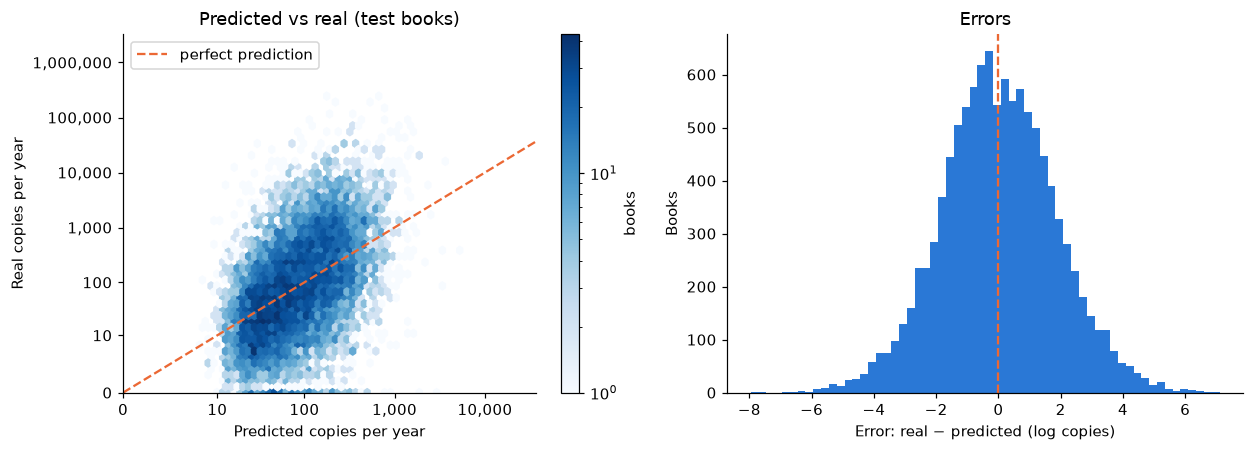

Predicted copies: from 6 to 5,263; real: from 0 to 244,707
Within 2 times of the real copies: 29.6% of test books
Sold more than predicted: 49.3%


In [8]:
errors = y_test - test_prediction
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
image = axes[0].hexbin(test_prediction, y_test, gridsize=45, cmap="Blues", mincnt=1, bins="log")
axes[0].plot([0, 10.5], [0, 10.5], color=ORANGE, linestyle="--", label="perfect prediction")
ticks = [0, 10, 100, 1000, 10000, 100000, 1000000]
axes[0].set_xticks(np.log1p(ticks[:5]), [f"{t:,}" for t in ticks[:5]])
axes[0].set_yticks(np.log1p(ticks), [f"{t:,}" for t in ticks])
axes[0].set_xlim(0, 10.5)
axes[0].set_ylim(0, 15)
axes[0].set_xlabel("Predicted copies per year")
axes[0].set_ylabel("Real copies per year")
axes[0].set_title("Predicted vs real (test books)")
axes[0].legend(loc="upper left")
fig.colorbar(image, ax=axes[0], label="books")
axes[1].hist(errors, bins=60, color=BLUE)
axes[1].axvline(0, color=ORANGE, linestyle="--")
axes[1].set_xlabel("Error: real − predicted (log copies)")
axes[1].set_ylabel("Books")
axes[1].set_title("Errors")
plt.tight_layout()
plt.show()
print(f"Predicted copies: from {np.expm1(test_prediction.min()):.0f} to {np.expm1(test_prediction.max()):,.0f}; real: from {np.expm1(y_test.min()):.0f} to {np.expm1(y_test.max()):,.0f}")
print(f"Within 2 times of the real copies: {(errors.abs() <= np.log(2)).mean():.1%} of test books")
print(f"Sold more than predicted: {(errors > 0).mean():.1%}")

- The cloud follows the dashed line, but it is wide: for the same prediction, real sales go from 0 to tens of thousands.
- The model predicts only from **6** to **5,263** copies, while the real books go up to **244,707**. It never predicts a hit.
- It is within 2 times of the real copies for **29.6%** of the books. The errors are balanced: **49.3%** of the books sold more than predicted.

## 9. Error analysis

Where does the model do well or badly? For groups of test books I compare the **real median copies** with the **predicted median copies**,
and show R² and the typical error inside the group.

In [9]:
test_books["predicted_log"] = test_prediction
test_books["predicted_copies"] = np.expm1(test_prediction)
test_books["experience"] = pd.cut(test_books["author_earlier_books"], [-1, 0, 2, 9, np.inf],
                                  labels=["first book", "1-2 earlier", "3-9 earlier", "10+ earlier"])
test_books["group"] = np.where(test_books["hit"], "hit", np.where(test_books["less_known"], "less-known, no hit", "other"))


def group_report(column, minimum=300):
    rows = []
    for group, part in test_books.groupby(column, observed=True):
        if len(part) >= minimum:
            rows.append({column: group, "books": len(part), "real median": part[TARGET].median(),
                         "predicted median": part["predicted_copies"].median(),
                         "R2 (log)": r2_score(part["log_copies"], part["predicted_log"]),
                         "MAE (log)": mean_absolute_error(part["log_copies"], part["predicted_log"])})
    return pd.DataFrame(rows).set_index(column)


display(group_report("route").round(2))
display(group_report("experience").round(2))
display(group_report("group", minimum=50).round(2))
niche_report = group_report("niche").sort_values("R2 (log)", ascending=False)
pd.concat([niche_report.head(4), niche_report.tail(4)]).round(2)

,books,real median,predicted median,R2 (log),MAE (log)
route,,,,,
large publisher,1538,281.17,259.39,0.10,1.60
self-published,5329,40.12,40.44,0.19,1.36
small publisher,4148,115.21,115.31,0.11,1.53


,books,real median,predicted median,R2 (log),MAE (log)
experience,,,,,
first book,3834,35.46,37.16,0.13,1.37
1-2 earlier,2040,60.83,62.83,0.16,1.44
3-9 earlier,2130,81.89,101.43,0.14,1.53
10+ earlier,3011,255.52,201.80,0.09,1.53


,books,real median,predicted median,R2 (log),MAE (log)
group,,,,,
hit,101,24586.10,317.29,-44.65,4.64
"less-known, no hit",5855,42.71,44.82,0.16,1.38
other,5059,154.43,152.18,0.13,1.48


,books,real median,predicted median,R2 (log),MAE (log)
niche,,,,,
Religion & Spirituality,631,117.08,90.20,0.28,1.32
Teen & Young Adult,454,93.04,97.05,0.28,1.41
"Mystery, Thriller & Suspense",646,117.96,119.58,0.27,1.47
Literature & Fiction,3415,84.00,85.91,0.25,1.51
Children's eBooks,729,39.99,47.17,0.19,1.42
Romance,1155,140.32,151.54,0.14,1.39
History,320,62.67,78.16,0.07,1.58
Business & Money,589,58.40,53.61,0.07,1.34


- **Route and experience:** the predicted medians are close to the real ones (self-published **40 vs 40**, small publisher **115 vs 115**, first books **35 vs 37**).
  For authors with 10+ earlier books the model is too low (**202** against 256), and R² inside each group is low (0.09–0.19).
- **Hits:** the real median is **24,586** copies and the predicted one **317**. **Less-known authors without hits:** **43 vs 45**, R² 0.16.
- **Niches:** best in Religion & Spirituality, Teen & Young Adult and Mystery (R² 0.27–0.28), weakest in History and Business & Money (0.07).

I also look at the books with the largest errors in both directions.

In [10]:
show = ["title", "niche", "route", "price", "is_series", "author_earlier_books", TARGET, "predicted_copies"]
under = test_books.assign(error=errors).nlargest(5, "error")[show]
over = test_books.assign(error=errors).nsmallest(5, "error")[show]
rounding = {TARGET: 0, "predicted_copies": 0}
display(under.round(rounding))
display(over.round(rounding))
hits = test_books[test_books["hit"]]
print(f"Hits in the test: {len(hits):,} | real median {hits[TARGET].median():,.0f} | predicted median {hits['predicted_copies'].median():,.0f}")

,title,niche,route,price,is_series,author_earlier_books,copies_per_year,predicted_copies
19800,Think and Grow Rich!,Business & Money,small publisher,1.99,0,63,226795.0,186.0
12982,"Life Skills for Teens: How to Cook, Clean, Man...",Children's eBooks,self-published,3.99,0,1,35169.0,29.0
54590,The Lincoln Highway: A Novel,Literature & Fiction,small publisher,12.99,0,6,197722.0,213.0
20573,The Memory of an Elephant,Literature & Fiction,self-published,3.99,0,0,23889.0,25.0
14,A Christmas Carol: The Original Christmas Story,Children's eBooks,small publisher,9.99,0,5,80021.0,113.0


,title,niche,route,price,is_series,author_earlier_books,copies_per_year,predicted_copies
39514,Hometown Heartbreakers Collection Volume 2,Literature & Fiction,large publisher,14.99,1,272,0.0,2845.0
3528,Die Buchanans - 4-teilige Serie (eBundle) (Ger...,Literature & Fiction,small publisher,14.96,0,268,0.0,2011.0
6948,E-Pack HQN Susan Mallery 1 (Spanish Edition),Literature & Fiction,small publisher,8.99,0,286,0.0,896.0
18653,Here for You: A Clean and Wholesome Romance (F...,Literature & Fiction,large publisher,9.61,1,37,0.0,797.0
13816,Cita con la muerte (Spanish Edition),Literature & Fiction,small publisher,10.99,0,194,0.0,527.0


Hits in the test: 101 | real median 24,586 | predicted median 317


- **Too low:** classics and old bestsellers, for example *Think and Grow Rich!* (226,795 real against 186 predicted). Nothing in the features shows that a book is famous.
- **Too high:** big collections and translations from authors with hundreds of books that sold nothing in the data, for example a 272-book author's collection
  (0 real against 2,845 predicted).

## 10. Interpretation

**Permutation importance** shuffles one feature in the test books and measures how much R² falls. A large fall means the model relies on that
feature. I use 8,000 test books to keep this quick.

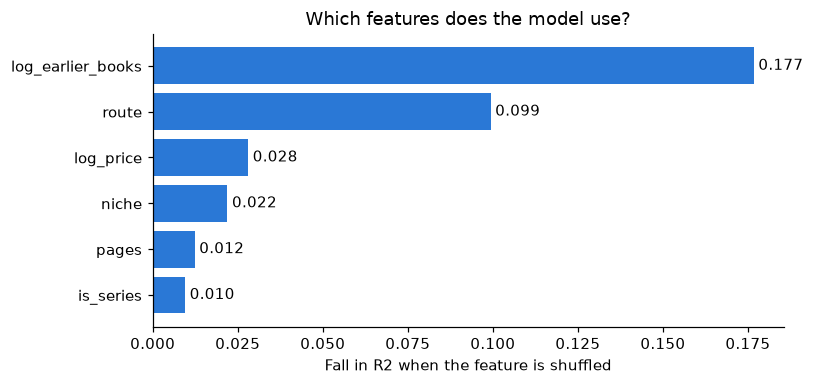

{'log_earlier_books': 0.177, 'route': 0.099, 'log_price': 0.028, 'niche': 0.022, 'pages': 0.012, 'is_series': 0.01}


In [11]:
sample = X_test.sample(8000, random_state=RANDOM_STATE)
importance = permutation_importance(best_model, sample, y_test.loc[sample.index], scoring="r2", n_repeats=5, random_state=RANDOM_STATE)
importance_table = pd.Series(importance.importances_mean, index=FEATURES, name="fall in R2").sort_values()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bars = ax.barh(importance_table.index, importance_table.values, color=BLUE)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xlabel("Fall in R2 when the feature is shuffled")
ax.set_title("Which features does the model use?")
plt.tight_layout()
plt.show()
print(importance_table.sort_values(ascending=False).round(3).to_dict())

- The model relies most on the **author's earlier books** (R² falls by **0.177**) and the **route** (0.099).
- **Price** (0.028), **niche** (0.022), **pages** (0.012) and **series** (0.010) add less.

The weights are on the log scale, so I turn them into **multipliers**: `exp(weight)` is how many times more copies the model expects, with other
features equal. Above 1 means more copies and below 1 fewer. For scaled features it is the change for one standard deviation. Niches are
compared with *Literature & Fiction* and routes with *self-published*.

,× copies
route: large publisher,3.85
route: small publisher,1.83
log_earlier_books,1.81
is_series,1.36
log_price,1.29
pages,1.18


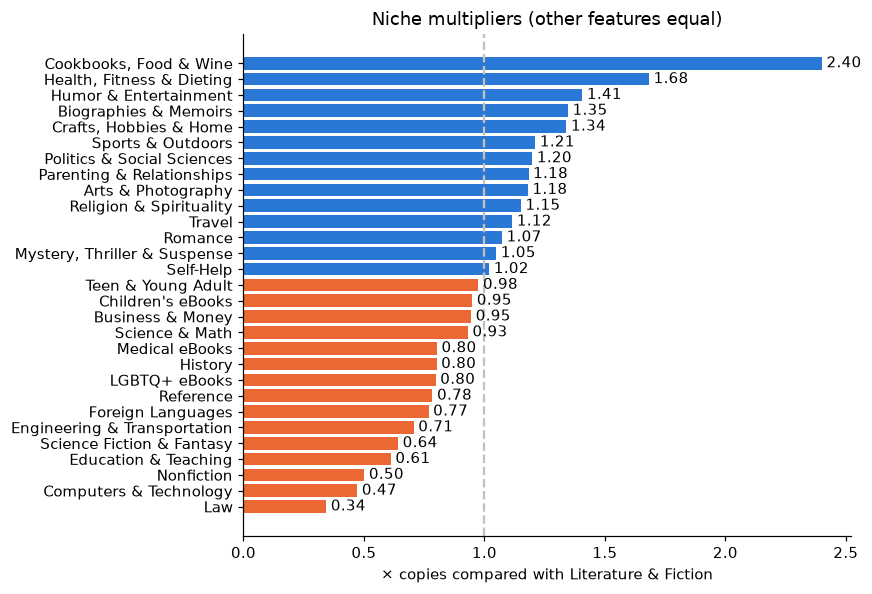

In [12]:
names = best_model.named_steps["prepare"].get_feature_names_out()
multiplier = pd.Series(np.exp(best_model.named_steps["model"].coef_), index=names, name="× copies")
multiplier.index = (multiplier.index.str.replace(r"^(continuous|binary|category)__", "", regex=True)
                    .str.replace("niche_", "niche: ").str.replace("route_", "route: "))
main = multiplier[~multiplier.index.str.startswith("niche:")].sort_values(ascending=False)
niche_multiplier = multiplier[multiplier.index.str.startswith("niche:")].sort_values(ascending=False)
display(main.round(2).to_frame())

fig, ax = plt.subplots(figsize=(8, 5.5))
colors = [BLUE if v >= 1 else ORANGE for v in niche_multiplier.values]
bars = ax.barh(niche_multiplier.index.str.replace("niche: ", ""), niche_multiplier.values, color=colors)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.axvline(1, color=GREY, linestyle="--")
ax.invert_yaxis()
ax.set_xlabel("× copies compared with Literature & Fiction")
ax.set_title("Niche multipliers (other features equal)")
plt.tight_layout()
plt.show()

- **Route:** a large publisher goes with **3.85 times** and a small publisher with **1.83 times** more copies than self-publishing.
- **Earlier books:** **1.81 times** more for one standard deviation. **Series:** **1.36 times**. Price (1.29) and pages (1.18) add less.
- **Niches:** Cookbooks, Food & Wine (**2.40**), Health, Fitness & Dieting (1.68) and Humor & Entertainment (1.41) are the highest; Law (**0.34**), Computers & Technology
  (0.47) and Nonfiction (0.50) the lowest, compared with Literature & Fiction.

Finally I give the model a few **invented book drafts** and look at the predicted copies a year. All have 250 pages unless the description
says otherwise.

In [13]:
examples = pd.DataFrame([
    ["Romance, self-published first book, 4.99", "Romance", 250, 4.99, 0, "self-published", 0],
    ["Same book in a series", "Romance", 250, 4.99, 1, "self-published", 0],
    ["In a series, author has 10 earlier books", "Romance", 250, 4.99, 1, "self-published", 10],
    ["First book, small publisher, 5.99", "Romance", 250, 5.99, 0, "small publisher", 0],
    ["First book, large publisher, 9.99", "Romance", 250, 9.99, 0, "large publisher", 0],
    ["Cookbook, self-published first book, 4.99", "Cookbooks, Food & Wine", 250, 4.99, 0, "self-published", 0],
    ["Mystery, self-published first book, 4.99", "Mystery, Thriller & Suspense", 250, 4.99, 0, "self-published", 0],
], columns=["draft", "niche", "pages", "price", "is_series", "route", "author_earlier_books"])
examples["predicted copies a year"] = np.expm1(best_model.predict(prepare_features(examples)[FEATURES]))
examples.drop(columns=["niche"]).round({"predicted copies a year": 0})

,draft,pages,price,is_series,route,author_earlier_books,predicted copies a year
0,"Romance, self-published first book, 4.99",250,4.99,0,self-published,0,30.0
1,Same book in a series,250,4.99,1,self-published,0,41.0
2,"In a series, author has 10 earlier books",250,4.99,1,self-published,10,109.0
3,"First book, small publisher, 5.99",250,5.99,0,small publisher,0,59.0
4,"First book, large publisher, 9.99",250,9.99,0,large publisher,0,149.0
5,"Cookbook, self-published first book, 4.99",250,4.99,0,self-published,0,68.0
6,"Mystery, self-published first book, 4.99",250,4.99,0,self-published,0,29.0


- A self-published first Romance book at 4.99 dollars gets about **30** copies a year; in a series **41**, and in a series by an author with 10 earlier books **109**.
- The same first book gets **59** copies with a small publisher and **149** with a large one. A self-published first **cookbook** gets **68**, a mystery **29**.
- These are **associations, not promises**.

## 11. Limitations & ethics

**Limitations**

- **The sales are synthetic.** Copies sold were made from the number of ratings (`03`), so the model learns mostly what goes with ratings. With real sales
  data the numbers would change; the method would stay the same.
- **Price is not a cause here.** In this data more expensive books are often publisher books and books by known authors, so the model links a higher price
  with more copies. In a real shop a higher price usually means fewer copies. The model shows associations, not what happens if an author changes the price.
- **Hits cannot be predicted.** Nothing in the draft tells which book will sell tens of thousands of copies.
- `route` and `author_earlier_books` come from my rules and count only books in this catalog. Some "authors" are really companies.
- Marketing, cover, writing quality and reviews are not in the data. The books are from 2019–2021.

**Ethics**

- The model favours experienced authors and publishers. It should not decide which authors or books deserve support.
- A low prediction does not mean that a book is bad. It is meant as **rough information for an author**, not a promise of income.

## 12. Conclusion

I save the test predictions, the main results and the trained model for the comparison notebook.

In [14]:
output = test_books[["parent_asin", TARGET, "log_copies", "predicted_log", "predicted_copies", "niche", "route", "price",
                     "author_earlier_books", "author_per_copy", "author_income", "hit", "less_known"]]
output.to_parquet(PROCESSED / "predictions_sales_linear_regression.parquet", index=False)
summary = {"model": "Linear regression", "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
           "cv_r2": float(search.best_score_), "cv_std": float(search.cv_results_["std_test_score"][search.best_index_]),
           "train_r2": float(r2_score(y_train, train_prediction)),
           "importance": {k: float(v) for k, v in importance_table.sort_values(ascending=False).items()}}
(PROCESSED / "results_sales_linear_regression.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
joblib.dump(best_model, MODELS_DIR / "sales_linear_regression.joblib")
print("Saved predictions:", output.shape)
print(f"Saved model: models/sales_linear_regression.joblib ({(MODELS_DIR / 'sales_linear_regression.joblib').stat().st_size / 1e6:.1f} MB)")

Saved predictions: (11015, 13)
Saved model: models/sales_linear_regression.joblib (0.0 MB)


- Linear regression explains **22.4%** of the differences in copies between test books, against 0% for the baseline, and is stable (train 0.219, test 0.224).
- The route and the author's experience matter most; among niches, practical non-fiction goes with more copies.
- It cannot predict hits, and its typical error in copies is not smaller than the baseline's. Next: `06.2_random_forest.ipynb`.